# MNIST Denoising

Can a small convolutional network pull a handwritten digit back out of heavy random noise?

Removing noise is the core step of **diffusion models**, the image generators behind tools such as DALL·E 2 and Midjourney. They start from pure noise and remove a little of it at a time until an image appears. This notebook studies that step on MNIST:

1. Data
2. Noise
3. The denoiser
4. Training
5. Measuring the results
6. Results
7. Try a digit
8. From pure noise to new digits

Training takes about 15 minutes on a CPU. The trained models are saved in `models/`, and later runs load them instead of training again.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from scipy.ndimage import gaussian_filter

SEED = 42
keras.utils.set_random_seed(SEED)
MODELS, ASSETS = Path("models"), Path("assets")
MODELS.mkdir(exist_ok=True)
ASSETS.mkdir(exist_ok=True)

# Chart style
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, NEUTRAL = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10.5,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "grid.color": GRID, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(ASSETS / f"{name}.png", dpi=150, bbox_inches="tight")

def image_grid(rows, row_labels, col_titles=None, scale=0.95, title=None):
    # rows: list of image arrays, each (n, 28, 28, 1); one figure row per array
    n_rows, n_cols = len(rows), len(rows[0])
    label_width = 1.3 if any(row_labels) else 0.0
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * scale + label_width, n_rows * scale + (0.5 if title else 0.1)),
                             squeeze=False, gridspec_kw={"wspace": 0.06, "hspace": 0.08})
    for r, (images, label) in enumerate(zip(rows, row_labels)):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.imshow(np.clip(images[c, :, :, 0], 0, 1), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if r == 0 and col_titles is not None:
                ax.set_title(col_titles[c], fontsize=9.5, fontweight="normal", loc="center", color=INK_2)
        axes[r, 0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10, color=INK, labelpad=8)
    if not any(row_labels):
        fig.subplots_adjust(left=0.01, right=0.99)
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=INK)
    return fig

## 1. Data

MNIST has 70,000 handwritten digits, each 28 × 28 pixels. The last 5,000 training images are held back for validation, and the 10,000 test images are used only for the final results.

In [2]:
(x_train_all, y_train_all), (x_test, y_test) = keras.datasets.mnist.load_data()

def to_float(images):
    # uint8 pixels (0-255) to float32 in [0, 1], with a channel axis
    return (images.astype("float32") / 255.0)[..., None]

x_train_all, x_test = to_float(x_train_all), to_float(x_test)
x_train, y_train = x_train_all[:-5000], y_train_all[:-5000]
x_val, y_val = x_train_all[-5000:], y_train_all[-5000:]
print(f"Training {len(x_train):,} · validation {len(x_val):,} · test {len(x_test):,} images")

Training 55,000 · validation 5,000 · test 10,000 images


## 2. Noise

Noise is Gaussian: every pixel gets a random amount added, with standard deviation σ. Pixels run from 0 (black) to 1 (white), so at **σ = 1 the noise is as large as the whole black-to-white range**. Noisy pixels can fall below 0 or above 1; they are clipped only for display and scoring.

The denoiser is trained on noise levels from 0 to 1.5. It is tested at six levels, including σ = 2, which is stronger than anything it saw in training.

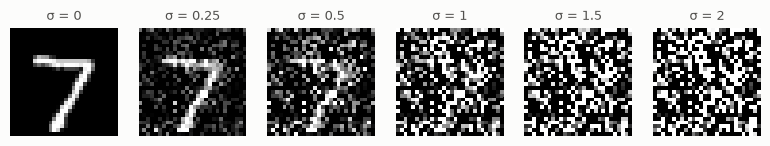

In [3]:
SIGMA_MAX = 1.5                                  # training noise: σ drawn uniformly from 0 to SIGMA_MAX
TEST_SIGMAS = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0]   # 2.0 is beyond the training range

def add_noise(images, sigma, seed):
    rng = np.random.default_rng(seed)
    return images + sigma * rng.standard_normal(images.shape, dtype=np.float32)

def noise_seed(sigma):
    # every method is scored on exactly the same noisy test images
    return int(sigma * 1000)

levels = [0, 0.25, 0.5, 1.0, 1.5, 2.0]
digit = x_test[:1]
fig = image_grid([np.concatenate([add_noise(digit, s, seed=1) for s in levels])], [""],
                 col_titles=[f"σ = {s:g}" for s in levels], scale=1.3)
save(fig, "noise-levels")
plt.show()

## 3. The denoiser

A small **U-Net**, the same kind of network that diffusion models use. The encoder shrinks the image from 28 × 28 to 7 × 7 while adding channels, so it can recognise strokes and shapes. The decoder builds it back up. Skip connections carry fine detail from the encoder straight across to the decoder.

The network sees only the noisy image, never σ, so it has to judge the noise level itself. Its last layer is linear, and outputs are clipped to the 0–1 pixel range when used. (A sigmoid output layer saturated early in training in tests and got stuck predicting blank images.)

In [4]:
def conv_block(x, channels):
    x = layers.Conv2D(channels, 3, padding="same", activation="relu")(x)
    return layers.Conv2D(channels, 3, padding="same", activation="relu")(x)

def build_denoiser():
    noisy = keras.Input((28, 28, 1), name="noisy")
    skip1 = conv_block(noisy, 16)                                # 28 × 28 × 16
    skip2 = conv_block(layers.MaxPooling2D()(skip1), 32)         # 14 × 14 × 32
    middle = conv_block(layers.MaxPooling2D()(skip2), 64)        #  7 ×  7 × 64
    up2 = layers.Conv2DTranspose(32, 2, strides=2)(middle)       # 14 × 14
    up2 = conv_block(layers.Concatenate()([up2, skip2]), 32)
    up1 = layers.Conv2DTranspose(16, 2, strides=2)(up2)          # 28 × 28
    up1 = conv_block(layers.Concatenate()([up1, skip1]), 16)
    clean = layers.Conv2D(1, 1, name="clean")(up1)
    return keras.Model(noisy, clean, name="denoiser")

print(f"{build_denoiser().count_params():,} parameters")

116,753 parameters


## 4. Training

The denoiser learns from pairs of noisy input and clean target. Every batch gets **fresh random noise** at a random level between 0 and 1.5, so the network never sees the same noisy image twice and can't memorise the noise. The loss is mean squared error, the same quantity PSNR measures. A fixed noisy validation set tracks progress. The learning rate halves when the validation loss stalls, and training stops early once it stops improving.

Epoch 1/20


430/430 - 43s - 99ms/step - loss: 0.0259 - val_loss: 0.0204 - learning_rate: 0.0010


Epoch 2/20


430/430 - 39s - 90ms/step - loss: 0.0195 - val_loss: 0.0188 - learning_rate: 0.0010


Epoch 3/20


430/430 - 38s - 89ms/step - loss: 0.0184 - val_loss: 0.0178 - learning_rate: 0.0010


... (30 outputs left out)

Epoch 19/20


430/430 - 42s - 98ms/step - loss: 0.0156 - val_loss: 0.0154 - learning_rate: 5.0000e-04


Epoch 20/20


430/430 - 40s - 92ms/step - loss: 0.0156 - val_loss: 0.0153 - learning_rate: 5.0000e-04


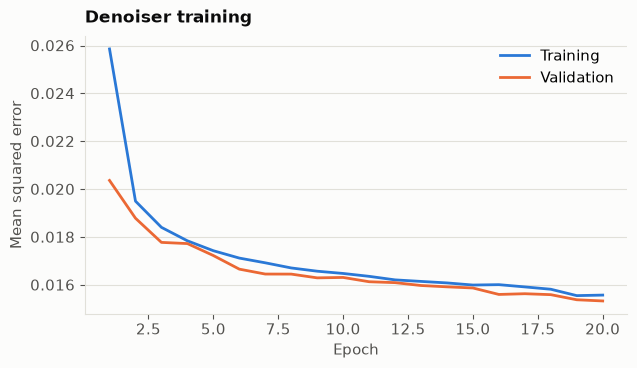

In [5]:
BATCH_SIZE = 128
EPOCHS = 20
RETRAIN = False   # True: train again even if models/denoiser.keras exists

def with_fresh_noise(clean):
    sigma = tf.random.uniform([tf.shape(clean)[0], 1, 1, 1], 0.0, SIGMA_MAX)
    return clean + sigma * tf.random.normal(tf.shape(clean)), clean

rng = np.random.default_rng(1)
val_sigma = rng.uniform(0, SIGMA_MAX, (len(x_val), 1, 1, 1)).astype("float32")
x_val_noisy = x_val + val_sigma * rng.standard_normal(x_val.shape, dtype=np.float32)

denoiser_path = MODELS / "denoiser.keras"
if denoiser_path.exists() and not RETRAIN:
    denoiser = keras.models.load_model(denoiser_path)
    print(f"Loaded {denoiser_path}")
else:
    train_data = (tf.data.Dataset.from_tensor_slices(x_train)
                  .shuffle(len(x_train), seed=SEED)
                  .batch(BATCH_SIZE)
                  .map(with_fresh_noise, num_parallel_calls=tf.data.AUTOTUNE)
                  .prefetch(tf.data.AUTOTUNE))
    denoiser = build_denoiser()
    denoiser.compile(optimizer=keras.optimizers.AdamW(1e-3, weight_decay=1e-4), loss="mse")
    history = denoiser.fit(
        train_data, validation_data=(x_val_noisy, x_val), epochs=EPOCHS, verbose=2,
        callbacks=[keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-5),
                   keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)],
    )
    denoiser.save(denoiser_path)

    fig, ax = plt.subplots(figsize=(7, 3.6))
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    ax.plot(epochs, history.history["loss"], color=BLUE, linewidth=2, label="Training")
    ax.plot(epochs, history.history["val_loss"], color=ORANGE, linewidth=2, label="Validation")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Mean squared error")
    ax.grid(axis="y"); ax.legend()
    ax.set_title("Denoiser training", pad=10)
    plt.show()

## 5. Measuring the results

Three things are compared at each noise level: the **noisy input** itself, a classic **Gaussian blur** filter, and the **denoiser**. The blur's strength is tuned on the validation set separately for each noise level, so it gets its best shot.

Each output is scored three ways:

- **PSNR** (peak signal-to-noise ratio, in decibels): how close the pixels are to the clean image. Higher is better; +10 dB means 10 times less squared error.
- **SSIM** (structural similarity, 0 to 1): how well local shapes and strokes match, closer to how people judge images.
- **Digit accuracy**: whether the digit is still the right digit. A separate classifier, trained only on clean images, reads each output; the score is the share it labels correctly.

In [6]:
def build_classifier():
    return keras.Sequential([
        keras.Input((28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dropout(0.3), layers.Dense(10, activation="softmax"),
    ], name="classifier")

classifier_path = MODELS / "classifier.keras"
if classifier_path.exists() and not RETRAIN:
    classifier = keras.models.load_model(classifier_path)
    print(f"Loaded {classifier_path}")
else:
    classifier = build_classifier()
    classifier.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    classifier.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=4, batch_size=128, verbose=2)
    classifier.save(classifier_path)

def predict_digits(images):
    return classifier.predict(np.clip(images, 0, 1), batch_size=512, verbose=0).argmax(axis=1)

clean_accuracy = (predict_digits(x_test) == y_test).mean()
print(f"Classifier accuracy on clean test digits: {clean_accuracy:.2%}")

Epoch 1/4


430/430 - 8s - 20ms/step - accuracy: 0.9029 - loss: 0.3279 - val_accuracy: 0.9780 - val_loss: 0.0762


Epoch 2/4


430/430 - 10s - 24ms/step - accuracy: 0.9705 - loss: 0.0935 - val_accuracy: 0.9866 - val_loss: 0.0533


Epoch 3/4


430/430 - 11s - 25ms/step - accuracy: 0.9794 - loss: 0.0696 - val_accuracy: 0.9898 - val_loss: 0.0442


Epoch 4/4


430/430 - 8s - 18ms/step - accuracy: 0.9822 - loss: 0.0585 - val_accuracy: 0.9910 - val_loss: 0.0367


Classifier accuracy on clean test digits: 98.70%


In [7]:
BLUR_WIDTHS = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0]

def blur(images, width):
    return gaussian_filter(images, sigma=(0, width, width, 0))

def denoise(images):
    return np.clip(denoiser.predict(images, batch_size=512, verbose=0), 0, 1)

def psnr(clean, output):
    return float(tf.reduce_mean(tf.image.psnr(clean, np.clip(output, 0, 1), max_val=1.0)))

def ssim(clean, output):
    return float(tf.reduce_mean(tf.image.ssim(clean, np.clip(output, 0, 1), max_val=1.0, filter_size=7)))

best_blur = {}
for sigma in TEST_SIGMAS:
    noisy_val = add_noise(x_val, sigma, seed=noise_seed(sigma) + 1)
    best_blur[sigma] = max(BLUR_WIDTHS, key=lambda w: psnr(x_val, blur(noisy_val, w)))
print("Best blur width (pixels) for each noise level:", best_blur)

Best blur width (pixels) for each noise level: {0.25: 0.75, 0.5: 1.0, 0.75: 1.25, 1.0: 1.5, 1.5: 2.5, 2.0: 3.0}


## 6. Results

In [8]:
METHODS = ["Noisy input", "Gaussian blur", "Denoiser"]
rows = []
for sigma in TEST_SIGMAS:
    noisy = add_noise(x_test, sigma, noise_seed(sigma))
    outputs = {"Noisy input": noisy, "Gaussian blur": blur(noisy, best_blur[sigma]), "Denoiser": denoise(noisy)}
    for method, output in outputs.items():
        rows.append({"σ": sigma, "method": method, "PSNR (dB)": psnr(x_test, output), "SSIM": ssim(x_test, output),
                     "digit accuracy": (predict_digits(output) == y_test).mean()})
results = pd.DataFrame(rows)

with pd.option_context("display.float_format", "{:.3f}".format):
    for metric in ["PSNR (dB)", "SSIM", "digit accuracy"]:
        display(results.pivot(index="σ", columns="method", values=metric)[METHODS].rename_axis(columns=metric))

PSNR (dB),Noisy input,Gaussian blur,Denoiser
σ,,,
0.250,14.856,18.852,25.207
0.500,9.377,15.702,21.257
0.750,7.098,13.987,18.904
1.000,5.984,12.844,17.208
1.500,4.940,11.542,14.939
2.000,4.453,10.760,13.625


SSIM,Noisy input,Gaussian blur,Denoiser
σ,,,
0.250,0.491,0.575,0.940
0.500,0.315,0.475,0.875
0.750,0.213,0.399,0.793
1.000,0.157,0.336,0.703
1.500,0.101,0.213,0.538
2.000,0.074,0.170,0.423


digit accuracy,Noisy input,Gaussian blur,Denoiser
σ,,,
0.250,0.973,0.978,0.984
0.500,0.560,0.942,0.973
0.750,0.218,0.836,0.936
1.000,0.135,0.705,0.871
1.500,0.111,0.390,0.683
2.000,0.103,0.277,0.531


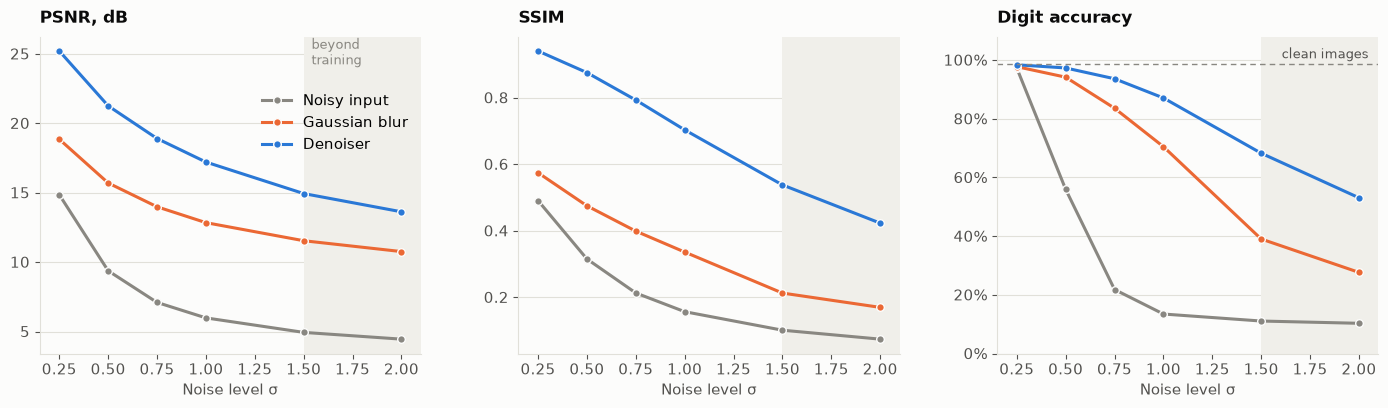

In [9]:
colors = {"Noisy input": NEUTRAL, "Gaussian blur": ORANGE, "Denoiser": BLUE}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, metric, label in zip(axes, ["PSNR (dB)", "SSIM", "digit accuracy"], ["PSNR, dB", "SSIM", "Digit accuracy"]):
    ax.axvspan(SIGMA_MAX, max(TEST_SIGMAS) + 0.1, color="#f0efea", linewidth=0)
    for method in METHODS:
        part = results[results.method == method]
        ax.plot(part["σ"], part[metric], color=colors[method], linewidth=2.2, marker="o", markersize=5.5,
                markeredgecolor=SURFACE, label=method)
    if metric == "digit accuracy":
        ax.axhline(clean_accuracy, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
        ax.annotate("clean images", (max(TEST_SIGMAS) + 0.05, clean_accuracy), xytext=(0, 4),
                    textcoords="offset points", ha="right", fontsize=9, color=INK_2)
        ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
        ax.set_ylim(0, 1.08)
    ax.set_xlim(0.15, max(TEST_SIGMAS) + 0.1)
    ax.set_xlabel("Noise level σ")
    ax.set_title(label, pad=10)
    ax.grid(axis="y"); ax.set_axisbelow(True)
axes[0].text(SIGMA_MAX + 0.04, axes[0].get_ylim()[1], "beyond\ntraining", va="top", fontsize=9, color=MUTED)
axes[0].legend(loc="upper right", bbox_to_anchor=(1.0, 0.86))
fig.tight_layout(w_pad=3)
save(fig, "quality-vs-noise")
plt.show()

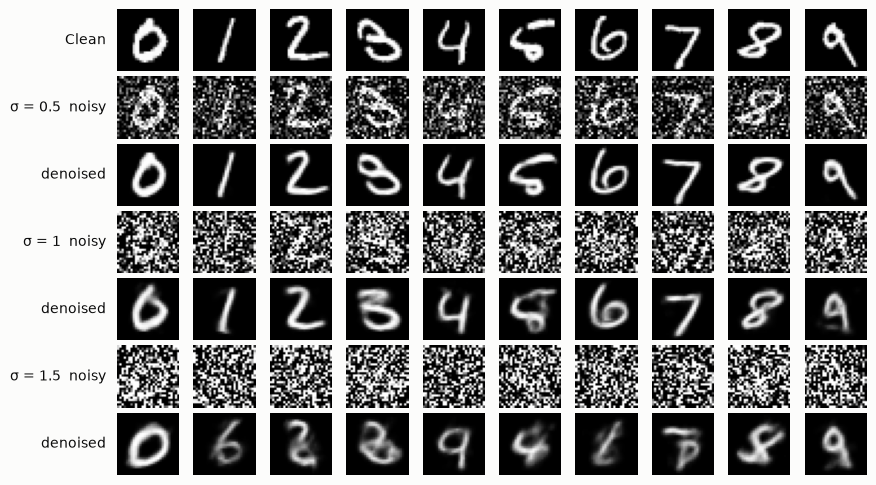

In [10]:
# One test example of each digit, at three noise levels
examples = np.array([np.flatnonzero(y_test == d)[0] for d in range(10)])
grid_rows, labels = [x_test[examples]], ["Clean"]
for sigma in [0.5, 1.0, 1.5]:
    noisy = add_noise(x_test, sigma, noise_seed(sigma))[examples]
    grid_rows += [noisy, denoise(noisy)]
    labels += [f"σ = {sigma:g}  noisy", "denoised"]
fig = image_grid(grid_rows, labels, scale=0.85)
save(fig, "denoising-examples")
plt.show()

### Mistakes

At σ = 1, which test digits does the denoiser turn into a different digit? These are digits the classifier reads correctly when clean but not after denoising.

1197 of 10,000 test digits (12.0%) change identity at σ = 1


,count
true → read as,
4 → 9,103
7 → 9,87
9 → 4,76
8 → 9,52
3 → 5,47
5 → 3,44
8 → 3,40
8 → 5,35


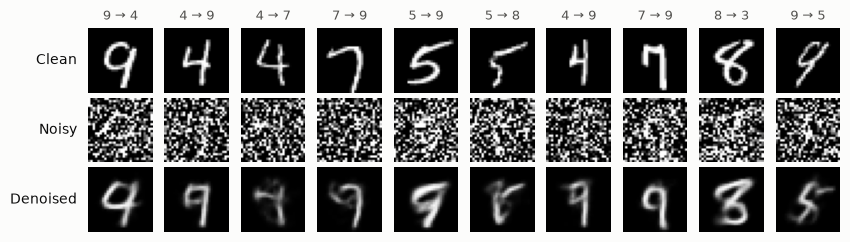

In [11]:
noisy_1 = add_noise(x_test, 1.0, noise_seed(1.0))
denoised_1 = denoise(noisy_1)
clean_pred, denoised_pred = predict_digits(x_test), predict_digits(denoised_1)
changed = np.flatnonzero((clean_pred == y_test) & (denoised_pred != y_test))
print(f"{len(changed)} of {len(y_test):,} test digits ({len(changed) / len(y_test):.1%}) change identity at σ = 1")

confusions = pd.Series([f"{y_test[i]} → {denoised_pred[i]}" for i in changed]).value_counts()
display(confusions.head(8).rename_axis("true → read as").rename("count").to_frame())

show = changed[:10]
fig = image_grid([x_test[show], noisy_1[show], denoised_1[show]], ["Clean", "Noisy", "Denoised"],
                 col_titles=[f"{y_test[i]} → {denoised_pred[i]}" for i in show], scale=0.85)
save(fig, "mistakes")
plt.show()

## 7. Try a digit

Pick a digit and a noise level: a random test image of that digit gets noise added, then the denoiser cleans it up and the classifier reads the result.

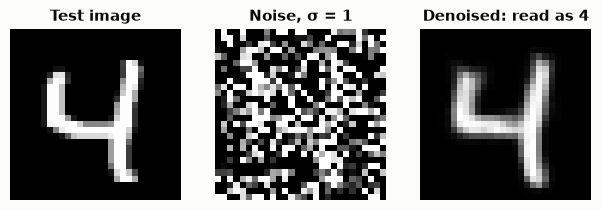

In [12]:
def try_digit(digit, sigma=1.0, seed=None):
    rng = np.random.default_rng(seed)
    image = x_test[rng.choice(np.flatnonzero(y_test == digit))][None]
    noisy = image + sigma * rng.standard_normal(image.shape, dtype=np.float32)
    cleaned = denoise(noisy)
    titles = ["Test image", f"Noise, σ = {sigma:g}", f"Denoised: read as {predict_digits(cleaned)[0]}"]
    fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.9))
    for ax, img, title in zip(axes, [image, noisy, cleaned], titles):
        ax.imshow(np.clip(img[0, :, :, 0], 0, 1), cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=10.5, loc="center")
        ax.axis("off")
    plt.show()

try_digit(4, sigma=1.0, seed=7)

## 8. From pure noise to new digits

A diffusion model creates an image by removing noise in many small steps rather than one big one. The trained denoiser can do the same:

1. Start from **pure noise**: the average training image with σ = 1.5 noise on top, so no digit is hidden in it.
2. Let the denoiser **guess the clean image**.
3. **Add back slightly less noise** than before, and repeat.

Over 40 steps the noise level falls from 1.5 to 0.02. Each guess is blurry at first, because the denoiser can only predict an average of the digits that might be under the noise. Each round of fresh noise pushes the image toward one particular digit, and the strokes sharpen as the noise falls.

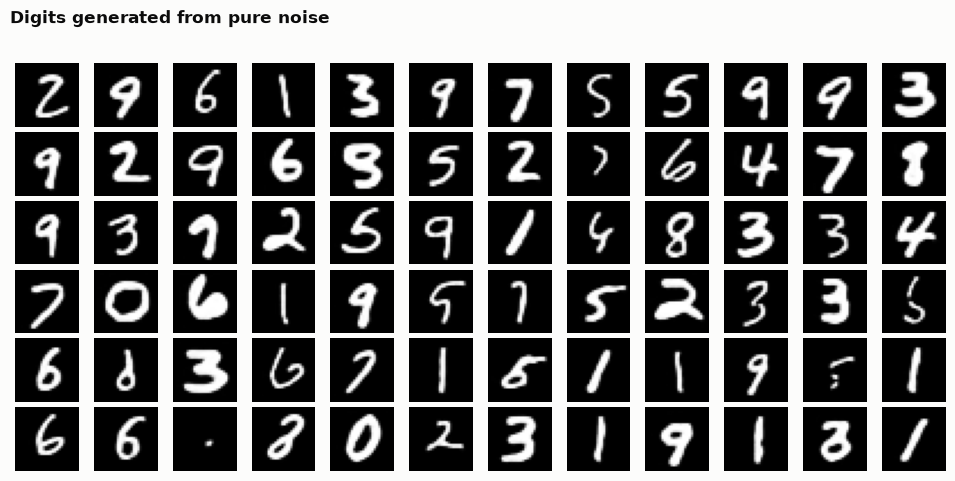

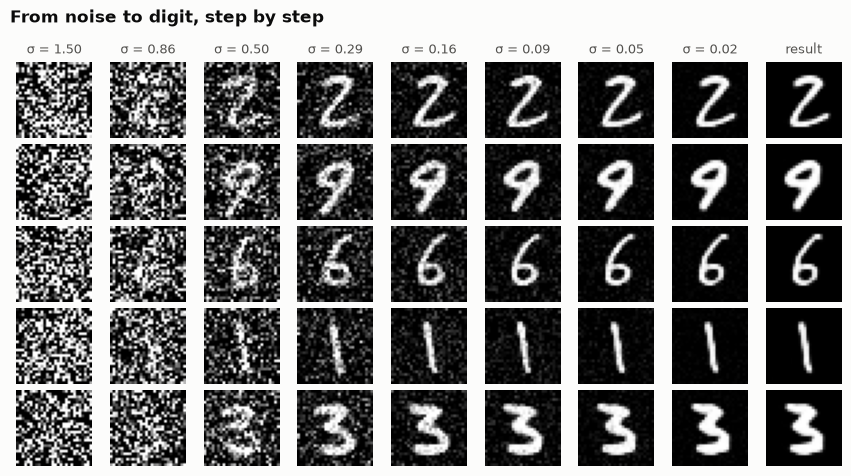

In [13]:
def generate(n, steps=40, seed=0, keep=()):
    rng = np.random.default_rng(seed)
    sigmas = np.geomspace(SIGMA_MAX, 0.02, steps)
    images = x_train.mean(axis=0) + SIGMA_MAX * rng.standard_normal((n, 28, 28, 1), dtype=np.float32)
    snapshots = {}
    for step, sigma in enumerate(sigmas):
        if step in keep:
            snapshots[step] = images.copy()
        guess = denoiser.predict(images, batch_size=512, verbose=0)
        if step + 1 < steps:
            images = guess + sigmas[step + 1] * rng.standard_normal(images.shape, dtype=np.float32)
    return np.clip(guess, 0, 1), sigmas, snapshots

STEPS_SHOWN = [0, 5, 10, 15, 20, 25, 30, 39]
generated, sigmas, snapshots = generate(1000, seed=SEED, keep=STEPS_SHOWN)

fig = image_grid([generated[r * 12:(r + 1) * 12] for r in range(6)], [""] * 6, scale=0.8,
                 title="Digits generated from pure noise")
save(fig, "generated-digits")
plt.show()

picks = [0, 1, 2, 3, 4]
fig = image_grid([np.stack([snapshots[s][i] for s in STEPS_SHOWN] + [generated[i]]) for i in picks], [""] * len(picks),
                 col_titles=[f"σ = {sigmas[s]:.2f}" for s in STEPS_SHOWN] + ["result"], scale=0.95,
                 title="From noise to digit, step by step")
save(fig, "generation-steps")
plt.show()

In [14]:
probabilities = classifier.predict(generated, batch_size=512, verbose=0)
confident = probabilities.max(axis=1) >= 0.9
labels_generated = probabilities.argmax(axis=1)
print(f"The classifier is at least 90% sure which digit it is for {confident.mean():.0%} of {len(generated):,} generated images")
display(pd.Series(labels_generated[confident]).value_counts().sort_index()
        .rename_axis("digit").rename("confident generated images").to_frame().T)

real_confident = (classifier.predict(x_test, batch_size=512, verbose=0).max(axis=1) >= 0.9).mean()
print(f"For comparison: {real_confident:.0%} of real test digits")

The classifier is at least 90% sure which digit it is for 90% of 1,000 generated images


digit,0,1,2,3,4,5,6,7,8,9
confident generated images,32,183,40,117,49,101,114,47,50,163


For comparison: 96% of real test digits


The generated digits come from a model that was never trained to generate anything: it only ever learned to clean up noisy images. Repeating that one skill many times, with less noise each time, turns noise into new digits. That is the core idea of a diffusion model. Real diffusion models add a much larger network, many more noise levels and, usually, a text or class input to steer what appears.